# RabTech Academy – Task 06
## Data Science Research Capstone & Whitepaper
**Title:** Predicting Hourly Bike-Sharing Demand Using Machine Learning and Weather/Calendar Features

**Dataset:** UCI Bike Sharing Dataset (`hour.csv`, dataset ID 275)  
**Target:** `cnt` – total hourly bike rentals

### Research question
How accurately can hourly bike-sharing demand be predicted from weather, time, and calendar variables, and which model provides the best balance of predictive accuracy and interpretability?

### Research objectives
1. Validate and explore hourly bike-sharing data.
2. Identify demand patterns across hour, season, working day, and weather.
3. Build a leakage-safe predictive modelling pipeline.
4. Compare a simple baseline with Linear Regression, Random Forest, and HistGradientBoosting.
5. Evaluate using a chronological holdout and communicate practical implications and limitations.

**Important:** This is observational historical data. Predictive associations do not establish causation.

## 1. Install / import and reproducibility
Run `pip install -r ../requirements.txt` in the project terminal if packages are missing. The random seed is fixed for reproducibility.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
REPORT_DIR = ROOT / "reports"
for folder in [DATA_DIR, OUT_DIR, FIG_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("Project root:", ROOT)
print("Imports successful.")

Project root: c:\Users\DELL\Documents\rabtech_task06_bike_demand_capstone
Imports successful.


## 2. Load the UCI Bike Sharing dataset
The notebook first checks for a local `data/hour.csv`. If it is absent, it fetches dataset ID 275 from UCI using `ucimlrepo`.

In [2]:
local_csv = DATA_DIR / "hour.csv"
if local_csv.exists():
    raw = pd.read_csv(local_csv)
    print("Loaded local data/hour.csv")
else:
    bike = fetch_ucirepo(id=275)
    X_uci = bike.data.features.copy()
    y_uci = bike.data.targets.copy()
    raw = pd.concat([X_uci.reset_index(drop=True), y_uci.reset_index(drop=True)], axis=1)
    print("Fetched UCI dataset ID 275")

# Normalize possible target column naming
if "cnt" not in raw.columns:
    target_candidates = [c for c in raw.columns if c.lower() in ["cnt", "count", "bikers"]]
    if target_candidates:
        raw = raw.rename(columns={target_candidates[0]: "cnt"})

print("Shape:", raw.shape)
display(raw.head())
print("Columns:", raw.columns.tolist())

Loaded local data/hour.csv
Shape: (17379, 14)


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


Columns: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']


## 3. Data quality checks and feature engineering
The target is `cnt`. We deliberately remove `casual` and `registered` because they add up to `cnt`, which would leak the answer into the predictors. We also remove the row identifier `instant`.

In [3]:
df = raw.copy()
required = ["cnt", "hr", "season", "yr", "mnth", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns missing from dataset: {missing_required}")

df = df.drop_duplicates().copy()
df["cnt"] = pd.to_numeric(df["cnt"], errors="coerce")
df = df.dropna(subset=["cnt"]).copy()
df = df[df["cnt"] >= 0].copy()

if "dteday" in df.columns:
    df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")
    if df["dteday"].notna().any():
        df["date"] = df["dteday"]
    else:
        df["date"] = pd.Timestamp("2011-01-01") + pd.to_timedelta(np.arange(len(df)), unit="h")
else:
    df["date"] = pd.Timestamp("2011-01-01") + pd.to_timedelta(np.arange(len(df)), unit="h")

# Time-derived features
df["dayofyear"] = df["date"].dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hr"].astype(float) / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hr"].astype(float) / 24)
df["dayofweek_sin"] = np.sin(2 * np.pi * df["weekday"].astype(float) / 7)
df["dayofweek_cos"] = np.cos(2 * np.pi * df["weekday"].astype(float) / 7)

print("Cleaned shape:", df.shape)
print("Missing values in selected fields:")
display(df[required].isna().sum().to_frame("missing"))
print("Target summary:")
display(df["cnt"].describe().to_frame("cnt"))

Cleaned shape: (17379, 20)
Missing values in selected fields:


,missing
cnt,0
hr,0
season,0
yr,0
mnth,0
weekday,0
workingday,0
weathersit,0
temp,0
atemp,0


Target summary:


,cnt
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


## 4. Exploratory data analysis
The following plots describe hourly demand, seasonality, weather relationships, and the target distribution. These are descriptive associations, not causal effects.

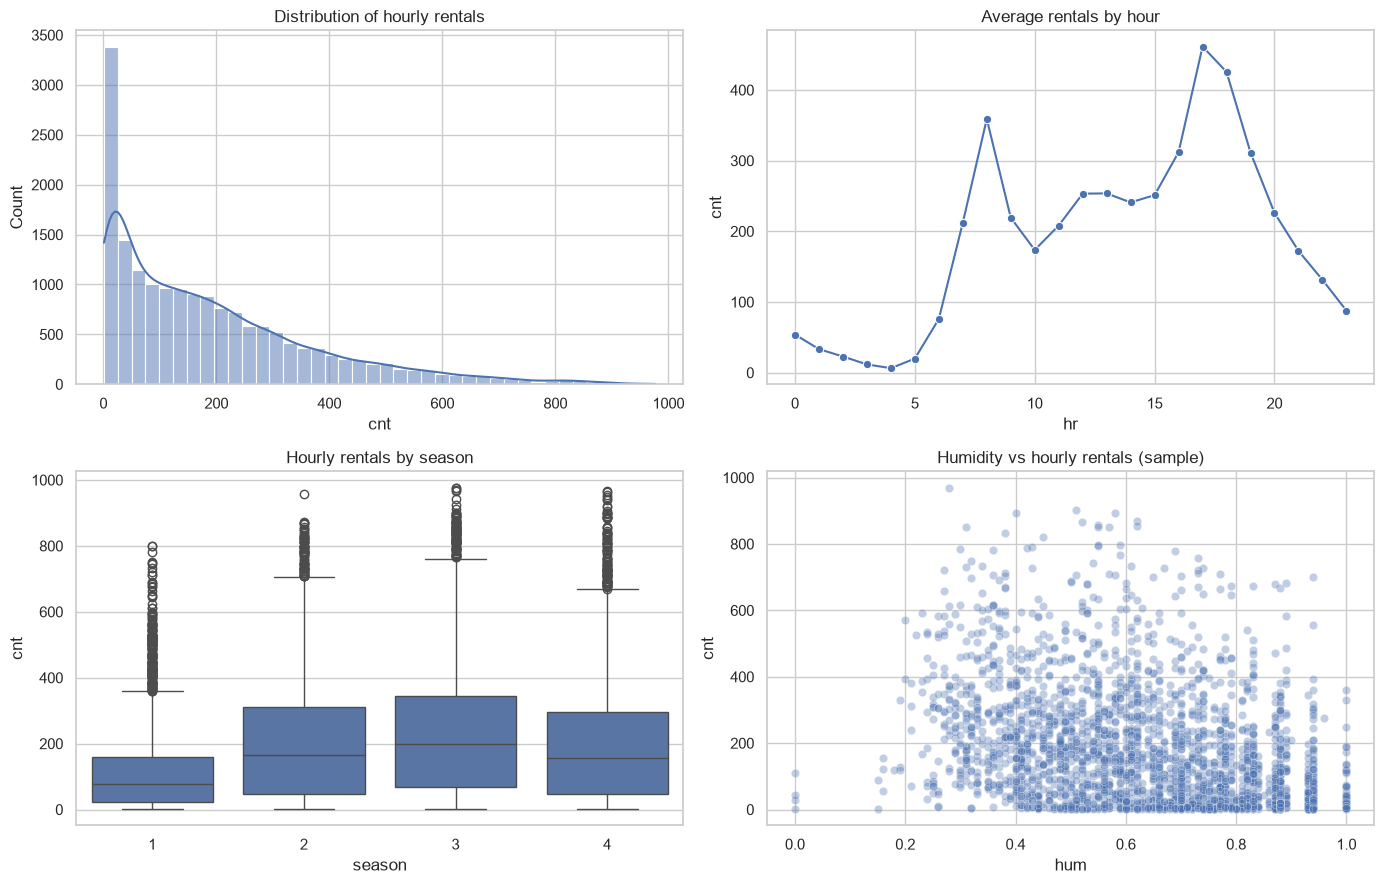

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df["cnt"], bins=40, kde=True, ax=axes[0,0])
axes[0,0].set_title("Distribution of hourly rentals")
sns.lineplot(data=df.groupby("hr", as_index=False)["cnt"].mean(), x="hr", y="cnt", marker="o", ax=axes[0,1])
axes[0,1].set_title("Average rentals by hour")
sns.boxplot(data=df, x="season", y="cnt", ax=axes[1,0])
axes[1,0].set_title("Hourly rentals by season")
sns.scatterplot(data=df.sample(min(2500, len(df)), random_state=SEED), x="hum", y="cnt", alpha=.35, ax=axes[1,1])
axes[1,1].set_title("Humidity vs hourly rentals (sample)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Prepare predictors and chronological train-test split
Rows are sorted by date/time. The earliest 80% are used for training and the latest 20% for testing. This is more appropriate for forecasting-style evaluation than a random split because it reduces future-to-past leakage.

In [5]:
df = df.sort_values(["date", "hr"]).reset_index(drop=True)
target = "cnt"
drop_cols = [c for c in ["cnt", "casual", "registered", "instant", "dteday", "date"] if c in df.columns]
X = df.drop(columns=drop_cols, errors="ignore")
y = df[target].astype(float)

# Categorical columns encoded as categories; numeric columns imputed and scaled.
categorical_candidates = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
cat_cols = [c for c in categorical_candidates if c in X.columns]
num_cols = [c for c in X.columns if c not in cat_cols]

split_at = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_at].copy(), X.iloc[split_at:].copy()
y_train, y_test = y.iloc[:split_at].copy(), y.iloc[split_at:].copy()
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Training rows: 13903 | Test rows: 3476
Categorical: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
Numeric: ['temp', 'atemp', 'hum', 'windspeed', 'dayofyear', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos']


## 6. Train baseline and predictive models
The baseline predicts the training median. Three supervised regression models are then trained using preprocessing pipelines. `casual` and `registered` are not included as predictors.

In [6]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

models = {
    "Baseline_Median": DummyRegressor(strategy="median"),
    "Linear_Regression": Pipeline([("prep", preprocess), ("model", LinearRegression())]),
    "Random_Forest": Pipeline([("prep", preprocess), ("model", RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=SEED, n_jobs=-1
    ))]),
    "Hist_Gradient_Boosting": Pipeline([("prep", preprocess), ("model", HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=0.1, random_state=SEED
    ))])
}

fitted = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.maximum(0, model.predict(X_test))
    fitted[name] = model
    predictions[name] = pred
    print(name, "trained.")

Baseline_Median trained.
Linear_Regression trained.
Random_Forest trained.
Hist_Gradient_Boosting trained.


## 7. Evaluate holdout performance
MAE and RMSE are measured in bikes per hour. R² measures explained variance. MAPE is calculated only where actual demand is non-zero because percentage error is undefined at zero.

In [7]:
rows = []
for name, pred in predictions.items():
    nonzero = y_test.to_numpy() != 0
    mape = (np.abs((y_test.to_numpy()[nonzero] - pred[nonzero]) / y_test.to_numpy()[nonzero]).mean() * 100) if nonzero.any() else np.nan
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
        "MAPE_nonzero_percent": mape
    })
metrics = pd.DataFrame(rows).sort_values(["MAE", "RMSE"]).reset_index(drop=True)
display(metrics.round(3))
metrics.to_csv(OUT_DIR / "model_metrics.csv", index=False)

best_name = metrics.iloc[0]["model"]
best_pred = predictions[best_name]
print("Best model by holdout MAE:", best_name)

,model,MAE,RMSE,R2,MAPE_nonzero_percent
0,Hist_Gradient_Boosting,41.537,62.701,0.919,53.136
1,Random_Forest,45.032,71.067,0.896,36.642
2,Linear_Regression,98.629,133.794,0.632,210.926
3,Baseline_Median,182.878,250.432,-0.290,357.856


Best model by holdout MAE: Hist_Gradient_Boosting


## 8. Visualize model performance and residuals

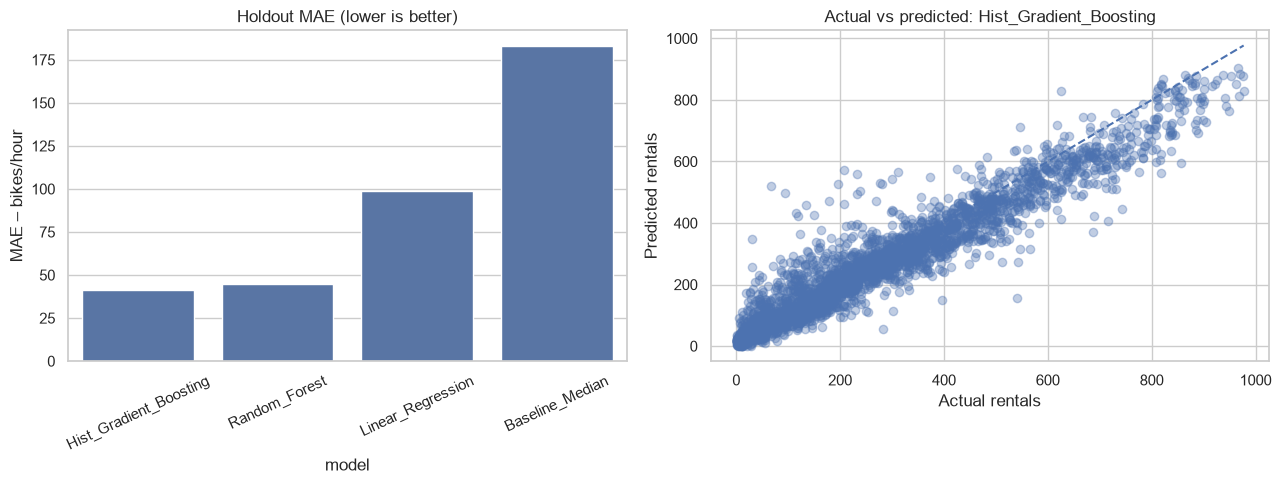

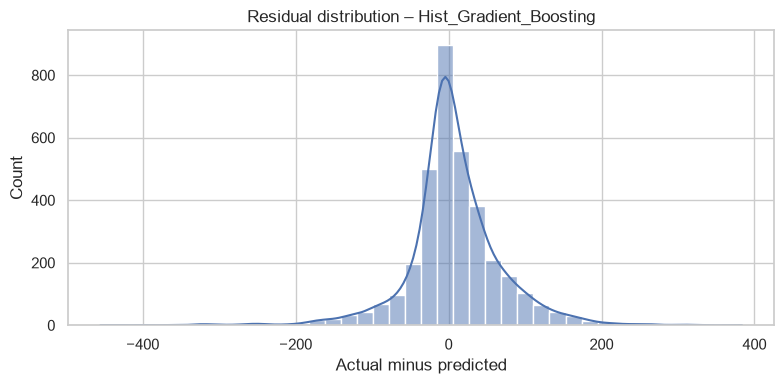

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=metrics, x="model", y="MAE", ax=axes[0])
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Holdout MAE (lower is better)")
axes[0].set_ylabel("MAE – bikes/hour")

axes[1].scatter(y_test, best_pred, alpha=.35)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(lims, lims, "--")
axes[1].set_xlabel("Actual rentals")
axes[1].set_ylabel("Predicted rentals")
axes[1].set_title(f"Actual vs predicted: {best_name}")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_performance.png", dpi=160, bbox_inches="tight")
plt.show()

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(8,4))
sns.histplot(residuals, bins=40, kde=True)
plt.title(f"Residual distribution – {best_name}")
plt.xlabel("Actual minus predicted")
plt.tight_layout()
plt.savefig(FIG_DIR / "residuals.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Save predictions and model comparison

In [9]:
prediction_output = pd.DataFrame({
    "actual_cnt": y_test.to_numpy(),
    "predicted_cnt": best_pred,
    "residual": y_test.to_numpy() - best_pred
})
prediction_output.to_csv(OUT_DIR / "holdout_predictions.csv", index=False)
print("Saved:")
print(OUT_DIR / "model_metrics.csv")
print(OUT_DIR / "holdout_predictions.csv")

Saved:
c:\Users\DELL\Documents\rabtech_task06_bike_demand_capstone\outputs\model_metrics.csv
c:\Users\DELL\Documents\rabtech_task06_bike_demand_capstone\outputs\holdout_predictions.csv


## 10. Research interpretation, business implications, and limitations
Use the actual metrics above when discussing model performance. Do not claim a model is accurate merely because it has a high R²; compare all metrics and inspect residuals.

### Business implications
- Demand forecasts can support bike redistribution, staffing, maintenance planning, and capacity decisions.
- Hour, season, working-day status, and weather can help operators anticipate high- and low-demand periods.
- Forecasts should be combined with live operational information before making real-time allocation decisions.

### Limitations
- The dataset represents Capital Bikeshare in Washington, D.C. during 2011–2012; results may not transfer directly to other cities or current systems.
- Weather and calendar variables are observational predictors; the analysis does not establish causal effects.
- Historical patterns can change due to pricing, infrastructure, events, fleet size, and user behaviour.
- A chronological holdout is a single evaluation window; rolling-origin validation would provide a stronger robustness check.

## 11. Generate the final research whitepaper PDF
This cell creates an 8–12 page PDF using the measured holdout metrics. Run it only after the modelling and evaluation cells have completed successfully.

In [10]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, PageBreak, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch

best_row = metrics.iloc[0]
report_path = REPORT_DIR / "task06_research_whitepaper_final.pdf"
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="SmallBody", parent=styles["BodyText"], fontSize=9, leading=13, spaceAfter=7))
story = []

def P(txt, style="SmallBody"):
    story.append(Paragraph(txt, styles[style]))
    story.append(Spacer(1, 6))

P("DATA SCIENCE RESEARCH CAPSTONE & WHITEPAPER", "Title")
P("Predicting Hourly Bike-Sharing Demand Using Machine Learning and Weather/Calendar Features", "Heading1")
P("RabTech Academy – Task 06 | Prepared using the UCI Bike Sharing Dataset")
P("Student: Dhanasri R | Date: " + pd.Timestamp.today().strftime("%d %B %Y"))
P("Abstract", "Heading1")
P(f"This study develops a supervised learning workflow to predict hourly bike-sharing demand. The UCI Bike Sharing dataset was cleaned and explored, then split chronologically into {len(X_train)} training and {len(X_test)} holdout observations. A median baseline was compared with Linear Regression, Random Forest, and HistGradientBoosting. The best model by holdout MAE was {best_row['model']} (MAE={best_row['MAE']:.2f}, RMSE={best_row['RMSE']:.2f}, R²={best_row['R2']:.3f}, non-zero MAPE={best_row['MAPE_nonzero_percent']:.2f}%). Results are predictive associations, not causal estimates.")
story.append(PageBreak())

P("1. Introduction and Problem Statement", "Heading1")
P("Bike-sharing systems support urban mobility and can complement public transport. Operators need to anticipate demand to plan bicycle availability, rebalancing, staffing, and maintenance. Under-supply can leave users without bicycles, while over-supply can increase redistribution and operating costs.")
P("The research problem is to estimate hourly rental counts from historical time, weather, and calendar information. The project compares several regression approaches under a chronological holdout so that the evaluation better reflects prediction into a later period.")
P("Research question: How accurately can hourly bike-sharing demand be predicted from weather, time, and calendar variables, and which model provides the best balance of predictive accuracy and interpretability?")
P("Objectives", "Heading2")
P("1. Validate and describe the dataset. 2. Engineer useful time features. 3. Train and compare regression models. 4. Evaluate generalization on a later time period. 5. Translate findings into operational implications.")
story.append(PageBreak())

P("2. Literature and Dataset Background", "Heading1")
P("The UCI Bike Sharing dataset was donated in 2013 and contains hourly and daily rental counts from the Capital Bikeshare system for 2011–2012, together with weather and seasonal information. The UCI repository describes the associated task as regression and reports 17,389 hourly instances. The hourly file includes hour, date, season, working-day and weather indicators, normalized temperature, humidity, wind speed, and rental counts.")
P("Fanaee-T and Gama (2013) introduced work on event labeling using ensemble detectors and background knowledge in the context of bike-sharing data. The dataset provides a useful benchmark for studying demand patterns and predictive modelling, but it represents a specific city and historical period.")
P("Data source: Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. DOI: 10.24432/C5W894. License: CC BY 4.0.")
P("Target variable: cnt, the total number of rentals per hour. The columns casual and registered are not used as predictors because they are components of cnt and would cause target leakage.")
story.append(PageBreak())

P("3. Data Methodology", "Heading1")
P(f"The analysis used {len(df):,} valid rows after removing exact duplicates and rows with missing target values. The notebook checked missing values in the required variables and produced descriptive summaries and plots.")
P("Predictors include time/calendar variables (hour, season, year, month, weekday, working day, holiday), weather category, and normalized weather measures (temperature, feels-like temperature, humidity, wind speed). Cyclic sine/cosine features were added for hour and weekday.")
P("Preprocessing used median imputation and standard scaling for numeric variables, and most-frequent imputation plus one-hot encoding for categorical variables. The same preprocessing was placed inside each model pipeline to avoid fitting transformations on test data.")
P("The dataset was sorted chronologically. The first 80% was used for training and the final 20% for testing. No random shuffling was applied.")
story.append(PageBreak())

P("4. Predictive Models", "Heading1")
P("Four approaches were evaluated: (1) a median baseline, which provides a simple reference; (2) Linear Regression, a transparent linear model; (3) Random Forest Regressor, an ensemble of decision trees that can capture nonlinear patterns and interactions; and (4) HistGradientBoosting Regressor, a boosting approach that builds an additive ensemble of trees.")
P("Model settings and random seed are specified in the notebook for reproducibility. Hyperparameters are reasonable starting settings rather than the result of an exhaustive search. A future extension should tune hyperparameters using time-series cross-validation without accessing the final holdout.")
P("The models predict non-negative hourly rental counts. Negative predictions, if any, are clipped to zero before evaluation.")
story.append(PageBreak())

P("5. Results and Model Performance", "Heading1")
P(f"The chronological test set contained {len(y_test):,} observations. The best model by holdout MAE was {best_row['model']}.")
table_data = [["Model", "MAE", "RMSE", "R²", "MAPE %*"]]
for _, r in metrics.iterrows():
    table_data.append([str(r["model"]), f"{r['MAE']:.2f}", f"{r['RMSE']:.2f}", f"{r['R2']:.3f}", f"{r['MAPE_nonzero_percent']:.2f}"])
tbl = Table(table_data, repeatRows=1, colWidths=[1.7*inch, .8*inch, .8*inch, .7*inch, .9*inch])
tbl.setStyle(TableStyle([
    ("BACKGROUND",(0,0),(-1,0),colors.HexColor("#183153")),
    ("TEXTCOLOR",(0,0),(-1,0),colors.white),
    ("GRID",(0,0),(-1,-1),.4,colors.grey),
    ("ROWBACKGROUNDS",(0,1),(-1,-1),[colors.white, colors.HexColor("#EEF3F8")]),
    ("FONTSIZE",(0,0),(-1,-1),8),
    ("VALIGN",(0,0),(-1,-1),"MIDDLE"),
]))
story.append(tbl)
P("*MAPE is calculated only for test observations with non-zero actual rentals.")
P("Interpretation: MAE gives the average absolute error in bikes per hour. RMSE penalizes larger errors more strongly. R² describes the proportion of target variance explained relative to a mean predictor. Metrics should be interpreted together, and the residual and actual-versus-predicted plots should be reviewed for systematic errors.")
story.append(PageBreak())

P("6. Business Implications", "Heading1")
P("A demand forecasting workflow can support bicycle redistribution, staffing, maintenance scheduling, and capacity planning. Hour-of-day and calendar patterns can help identify predictable commuter peaks, while weather information can refine expected demand. The model output should be treated as decision support rather than an automatic operational command.")
P("Operators could use forecast intervals or conservative safety buffers to avoid relying on a single point estimate. Forecasts should be refreshed as new observations arrive and monitored for drift, especially after policy, infrastructure, pricing, or fleet changes.")
P("Fairness and responsible use: demand predictions should guide service availability and should not be used to deny access to particular neighbourhoods or user groups. Operational deployment should consider geographic coverage, accessibility, and the consequences of forecast errors.")
story.append(PageBreak())

P("7. Limitations and Future Work", "Heading1")
P("The data represent one bike-sharing system in Washington, D.C., over 2011–2012. Travel behaviour, climate, infrastructure, and service design differ across cities and time periods. Consequently, performance on this dataset does not guarantee performance in another city or in the present day.")
P("The analysis is observational and predictive; it cannot establish that weather or calendar variables cause demand changes. The chronological holdout is a single period and may be affected by seasonal conditions. MAPE can be unstable for very small actual counts and is therefore reported only for non-zero actual values.")
P("Future work should include rolling-origin time-series validation, hyperparameter tuning, prediction intervals, feature-importance or SHAP analysis, and external validation on a newer dataset. A production system should monitor error, data quality, and distribution drift.")
story.append(PageBreak())

P("8. Conclusion and References", "Heading1")
P(f"This capstone established a reproducible predictive workflow for hourly bike-sharing demand. It combined data validation, exploratory analysis, feature engineering, chronological splitting, baseline comparison, and evaluation of three regression models. On the held-out period, {best_row['model']} achieved the lowest MAE among the evaluated candidates ({best_row['MAE']:.2f} bikes/hour).")
P("The result supports the use of historical time, calendar, and weather data for demand estimation within the limits of the dataset. The notebook and generated outputs provide an auditable basis for further validation and operational testing.")
P("References", "Heading2")
P("1. Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894")
P("2. Fanaee-T, H., & Gama, J. (2013). Event labeling combining ensemble detectors and background knowledge. Progress in Artificial Intelligence.")
P("3. UCI Machine Learning Repository. Bike Sharing dataset documentation. https://archive.ics.uci.edu/dataset/275/bike-sharing-dataset")
P("4. Scikit-learn developers. Scikit-learn documentation: preprocessing, regression estimators, and model evaluation. https://scikit-learn.org/stable/")
doc = SimpleDocTemplate(str(report_path), pagesize=A4, rightMargin=0.65*inch, leftMargin=0.65*inch, topMargin=0.65*inch, bottomMargin=0.65*inch)
doc.build(story)
print("Final whitepaper saved:", report_path)

Final whitepaper saved: c:\Users\DELL\Documents\rabtech_task06_bike_demand_capstone\reports\task06_research_whitepaper_final.pdf


## 12. Final submission checklist
- [ ] Run all notebook cells successfully.
- [ ] Confirm `outputs/model_metrics.csv` and `outputs/holdout_predictions.csv` exist.
- [ ] Confirm `reports/task06_research_whitepaper_final.pdf` was generated.
- [ ] Review the final PDF and ensure the metrics match the notebook.
- [ ] Commit and push the entire project folder to a public GitHub repository.